# A Chirped Gaussian Wave Packet on Six Qubits

**Colin Casey, 2026.** The state used in `projects/tdgsa_qis` (`qgs.cpp`, `qgs.cu`, Section 8b of the TDGSA notebook), studied properly: SymPy derives its properties in closed form, Qiskit checks them on the actual 64-amplitude state, and Lean proves the index bookkeeping.

$$|\psi\rangle = \frac{1}{\mathcal N}\sum_{j=0}^{63} \psi(x_j)\,|j\rangle, \qquad \psi(x) = \exp\!\Big(-\frac{x^2}{4\sigma^2} + i\,\frac{c\,x^2}{4}\Big), \qquad \sigma = 2,\ c = 0.15$$

| Section | Question |
|---|---|
| 1. In plain English | What is this state, and why "chirped"? |
| 2. Position: width and normalization | How wide is it, and what is $\mathcal N$? |
| 3. The chirp: local wavenumber | What does $e^{icx^2/4}$ do? |
| 4. Momentum space and uncertainty | Why does a chirp *raise* $\sigma_x\sigma_k$ above the Heisenberg minimum? |
| 5. Compressing the chirp with dispersion | Which dispersion squeezes the packet to its narrowest? |
| 6. The 64-amplitude state in Qiskit | Do the closed forms hold on six qubits? |
| 7. What's special about qubits | Entanglement between the qubits, and what the chirp costs in gates |
| 8. Lean 4 | Index bookkeeping, proved |

Kernel: **py312**.

In [1]:
import subprocess, pathlib
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QFTGate, DiagonalGate, StatePreparation
from qiskit.quantum_info import Statevector, partial_trace, entropy
sp.init_printing(use_latex='mathjax')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})
NQ, DIM, SIGMA, CHIRP = 6, 64, 2.0, 0.15

---
## 1. In plain English

Six qubits have $2^6 = 64$ basis states. Read the index $j$ as a **position** on a ring of 64 sites. The state is a wave packet sitting on that ring:
- **Gaussian:** its *size* is a bell curve about 2 sites wide, so measuring it almost always gives a position near the center.
- **Chirped:** its *phase* grows like $x^2$. The local wavelength changes across the packet, short on one side and long on the other, like a chirped laser pulse whose color sweeps in time.

Measuring positions shows only the bell curve; the chirp is invisible. That's why the phase-retrieval notebooks measure a second time after a dispersion circuit.

---
## 2. Position: width and normalization

In [2]:
x = sp.symbols('x', real=True)
k, a = sp.symbols('k a', real=True)
sig, c = sp.symbols('sigma c', positive=True)
psi = sp.exp(-x**2/(4*sig**2) + sp.I*c*x**2/4)
display(sp.Eq(sp.Symbol(r'\psi(x)'), psi))
prob = sp.simplify(psi*sp.conjugate(psi))
display(sp.Eq(sp.Symbol(r'|\psi(x)|^2'), prob))
print('-> the chirp drops out of the probability: measuring position cannot see it')
norm2 = sp.integrate(prob, (x, -sp.oo, sp.oo))
var_x = sp.simplify(sp.integrate(x**2*prob, (x, -sp.oo, sp.oo))/norm2)
display(sp.Eq(sp.Symbol(r'\int|\psi|^2dx'), norm2), sp.Eq(sp.Symbol(r'\sigma_x^2'), var_x))
N_cont = float(sp.sqrt(norm2).subs(sig, SIGMA))
xs = np.arange(DIM) - DIM//2
N_disc = np.sqrt(np.sum(np.exp(-xs**2/(2*SIGMA**2))))
print(f'normalization: continuous sqrt(sigma sqrt(2 pi)) = {N_cont:.10f};  64-site sum = {N_disc:.10f}  (sites are dense enough)')

                2     2 
           ⅈ⋅c⋅x     x  
           ────── - ────
             4         2
                    4⋅σ 
\psi(x) = ℯ             

                2 
              -x  
              ────
                 2
              2⋅σ 
|\psi(x)|² = ℯ    

-> the chirp drops out of the probability: measuring position cannot see it


\int|\psi|__2dx = √2⋅√π⋅σ

            2
\sigma²ₓ = σ 

normalization: continuous sqrt(sigma sqrt(2 pi)) = 2.2390302698;  64-site sum = 2.2390302698  (sites are dense enough)


---
## 3. The chirp: local wavenumber

Write $\psi = |\psi|e^{i\varphi(x)}$. The **local wavenumber** is the slope of the phase, $k_{loc}(x) = \varphi'(x)$, the spatial version of an optical pulse's instantaneous frequency.

In [3]:
phi = c*x**2/4
k_loc = sp.diff(phi, x)
display(sp.Eq(sp.Symbol(r'k_{loc}(x)'), k_loc))
print(f'with c = {CHIRP}: from x = -2 sigma to +2 sigma the local wavenumber sweeps',
      f'{float(k_loc.subs({c: CHIRP, x: -2*SIGMA})):+.2f} -> {float(k_loc.subs({c: CHIRP, x: 2*SIGMA})):+.2f} rad/site')
print('a linear sweep of wavenumber with position: that is what "linear chirp" means')

             c⋅x
k_{loc}(x) = ───
              2 

with c = 0.15: from x = -2 sigma to +2 sigma the local wavenumber sweeps -0.30 -> +0.30 rad/site
a linear sweep of wavenumber with position: that is what "linear chirp" means


---
## 4. Momentum space and uncertainty

Write $\psi = e^{-\alpha x^2}$ with complex $\alpha = \frac{1}{4\sigma^2} - \frac{ic}{4}$. Its Fourier transform is again Gaussian. SymPy finds the momentum spread and the uncertainty product:
$$\sigma_x\,\sigma_k = \frac12\sqrt{1 + c^2\sigma^4}\ \ge\ \frac12$$
Heisenberg's minimum $\tfrac12$ (in units $\hbar = 1$) is reached only without chirp. The chirp adds momentum spread without making the packet narrower: the extra wavenumbers are "spent" on the sweep.

In [4]:
alpha = 1/(4*sig**2) - sp.I*c/4
s = sp.symbols('s', positive=True)
gauss_ft = sp.integrate(sp.exp(-s*x**2)*sp.exp(sp.I*k*x), (x, -sp.oo, sp.oo))   # done for real s > 0 ...
phi_k = gauss_ft.subs(s, alpha)                                                   # ... then continued to complex alpha
display(sp.Eq(sp.Symbol(r'\tilde\psi(k)'), sp.simplify(phi_k)))
P_k = sp.simplify(sp.expand_complex(phi_k*sp.conjugate(phi_k)))
var_k = sp.simplify(sp.integrate(k**2*P_k, (k, -sp.oo, sp.oo))/sp.integrate(P_k, (k, -sp.oo, sp.oo)))
display(sp.Eq(sp.Symbol(r'\sigma_k^2'), sp.factor(var_k)))
product = sp.simplify(sp.sqrt(var_x*var_k))
display(sp.Eq(sp.Symbol(r'\sigma_x\sigma_k'), product))
print('at c = 0:', product.subs(c, 0), '  (the Heisenberg minimum)')
print(f'at sigma = {SIGMA}, c = {CHIRP}:', round(float(product.subs({sig: SIGMA, c: CHIRP})), 4))

                           2  2   
                          k ⋅σ    
                        ──────────
                             2    
                        ⅈ⋅c⋅σ  - 1
                2⋅√π⋅σ⋅ℯ          
\tilde\psi(k) = ──────────────────
                   ______________ 
                  ╱        2      
                ╲╱  - ⅈ⋅c⋅σ  + 1  

            2  4    
           c ⋅σ  + 1
\sigma²ₖ = ─────────
                2   
             4⋅σ    

                      ___________
                     ╱  2  4     
                   ╲╱  c ⋅σ  + 1 
\sigma_x\sigma_k = ──────────────
                         2       

at c = 0: 1/2   (the Heisenberg minimum)
at sigma = 2.0, c = 0.15: 0.5831


---
## 5. Compressing the chirp with dispersion

The dispersion operator from the phase-retrieval notebooks multiplies each momentum component by $e^{-iak^2}$. In optics, a chirped pulse sent through the right amount of dispersion is **compressed**; that's how chirped-pulse amplification and fiber compressors work. Same here: there is one value $a^\star$ where the packet is narrowest, and SymPy finds it.

In [5]:
alpha_a = alpha/(1 + 4*sp.I*a*alpha)             # psi(x, a) stays Gaussian with this complex width parameter
var_x_a = sp.simplify(1/(4*sp.re(sp.expand_complex(alpha_a))))
display(sp.Eq(sp.Symbol(r'\sigma_x^2(a)'), sp.factor(var_x_a)))
a_star = sp.solve(sp.diff(var_x_a, a), a)
a_star = [r_ for r_ in a_star if r_.is_real is not False][0]
display(sp.Eq(sp.Symbol('a^*'), sp.simplify(a_star)))
var_min = sp.simplify(var_x_a.subs(a, a_star))
display(sp.Eq(sp.Symbol(r'\sigma_{x,\min}^2'), sp.factor(var_min)))
vals = {sig: SIGMA, c: CHIRP}
print(f'sigma = {SIGMA}, c = {CHIRP}:  a* = {float(a_star.subs(vals)):.4f},  width {SIGMA:.3f} -> {float(sp.sqrt(var_min.subs(vals))):.4f} sites')
print('at the focus the product sigma_x sigma_k is back at 1/2: compression removes the chirp')

                  2  2  4    2          4    4
                 a ⋅c ⋅σ  + a  + 2⋅a⋅c⋅σ  + σ 
\sigma_x__2(a) = ─────────────────────────────
                               2              
                              σ               

            4   
        -c⋅σ    
a__* = ─────────
        2  4    
       c ⋅σ  + 1

                         2    
                        σ     
\sigma_{x,\min}__2 = ─────────
                      2  4    
                     c ⋅σ  + 1

sigma = 2.0, c = 0.15:  a* = -1.7647,  width 2.000 -> 1.7150 sites
at the focus the product sigma_x sigma_k is back at 1/2: compression removes the chirp


---
## 6. The 64-amplitude state in Qiskit

Now the real thing: 64 complex amplitudes on six qubits, rolled so that position 0 sits at index 0 (as in `qgs.cpp`). The momentum distribution comes from Qiskit's `QFTGate`; the dispersion from the same circuit as before, $\mathrm{QFT}^{-1}\,\mathrm{diag}(e^{-iak^2})\,\mathrm{QFT}$.

6-qubit state: sigma_x = 2.0000 (formula 2.0),  sigma_k = 0.2915 (formula 0.2915)
               product = 0.5831 (formula 0.5831)
after the dispersion circuit with a* = -1.765: sigma_x = 1.7150 (formula 1.7150);  product 0.5000


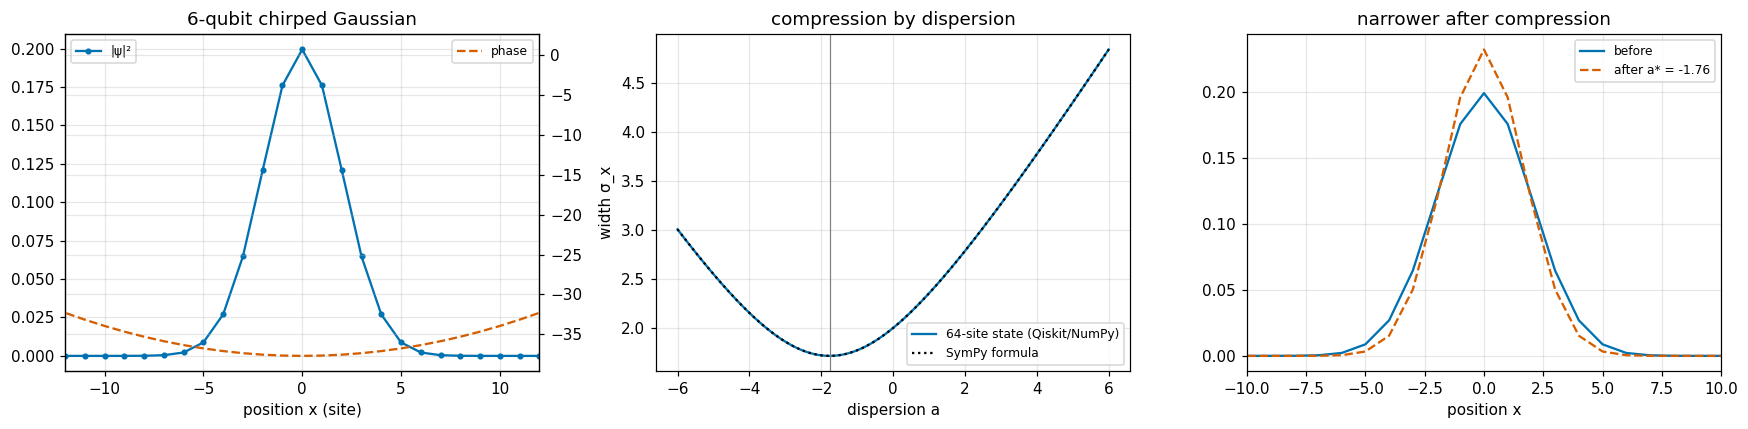

Figure: left, a bell curve of probability with a parabolic phase. Middle, the width versus dispersion dips to a minimum at a*, and the 64-site curve lies on the formula until the packet grows wide enough to wrap around the ring. Right, the compressed packet is taller and narrower than the original.


In [6]:
def chirped_state(chirp, sigma=SIGMA):
    v = np.roll(np.exp(-xs**2/(4*sigma**2) + 1j*chirp*xs**2/4), DIM//2)
    return v/np.linalg.norm(v)

kq = 2*np.pi*np.fft.fftfreq(DIM)
def D(av, v):                       # dispersion circuit, as a matrix-free NumPy operator (Qiskit QFTGate convention)
    return np.fft.fft(np.fft.ifft(v, norm='ortho')*np.exp(-1j*av*kq**2), norm='ortho')

def disp_circuit(av):
    qc = QuantumCircuit(NQ)
    qc.append(QFTGate(NQ), range(NQ)); qc.append(DiagonalGate(list(np.exp(-1j*av*kq**2))), range(NQ)); qc.append(QFTGate(NQ).inverse(), range(NQ))
    return qc

def moments(v):
    p = np.abs(v)**2; xpos = np.where(np.arange(DIM) < DIM//2, np.arange(DIM), np.arange(DIM) - DIM)
    sx = np.sqrt(np.sum(p*xpos**2) - np.sum(p*xpos)**2)
    qc = QuantumCircuit(NQ); qc.prepare_state(Statevector(v), range(NQ)); qc.append(QFTGate(NQ), range(NQ))
    pk = Statevector(qc).probabilities()
    sk = np.sqrt(np.sum(pk*kq**2) - np.sum(pk*kq)**2)
    return sx, sk

psi6 = chirped_state(CHIRP)
sx, sk = moments(psi6)
print(f'6-qubit state: sigma_x = {sx:.4f} (formula {SIGMA}),  sigma_k = {sk:.4f} (formula {float(sp.sqrt(var_k).subs(vals)):.4f})')
print(f'               product = {sx*sk:.4f} (formula {float(product.subs(vals)):.4f})')

a_opt = float(a_star.subs(vals))
qc = QuantumCircuit(NQ); qc.prepare_state(Statevector(psi6), range(NQ)); qc.compose(disp_circuit(a_opt), inplace=True)
compressed = Statevector(qc).data
print(f'after the dispersion circuit with a* = {a_opt:.3f}: sigma_x = {moments(compressed)[0]:.4f} '
      f'(formula {float(sp.sqrt(var_min).subs(vals)):.4f});  product {np.prod(moments(compressed)):.4f}')

a_scan = np.linspace(-6, 6, 121)
widths = [moments(D(av, psi6))[0] for av in a_scan]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
idx = np.argsort(np.where(np.arange(DIM) < 32, np.arange(DIM), np.arange(DIM) - DIM))
xpos = np.where(np.arange(DIM) < 32, np.arange(DIM), np.arange(DIM) - DIM)[idx]
ax[0].plot(xpos, np.abs(psi6[idx])**2, 'o-', ms=3, label='|ψ|²'); ax[0].set_xlim(-12, 12)
ax0b = ax[0].twinx(); ax0b.plot(xpos, np.unwrap(np.angle(psi6[idx])), '--', color='#D55E00', label='phase')
ax[0].set_xlabel('position x (site)'); ax[0].set_title('6-qubit chirped Gaussian'); ax[0].legend(loc='upper left', fontsize=8); ax0b.legend(loc='upper right', fontsize=8)
ax[1].plot(a_scan, widths, '-', label='64-site state (Qiskit/NumPy)')
ax[1].plot(a_scan, [float(sp.sqrt(var_x_a.subs(vals | {a: av}))) for av in a_scan], ':', color='k', label='SymPy formula')
ax[1].axvline(a_opt, color='gray', lw=0.8); ax[1].set_xlabel('dispersion a'); ax[1].set_ylabel('width σ_x'); ax[1].legend(fontsize=8)
ax[1].set_title('compression by dispersion')
ax[2].plot(xpos, np.abs(psi6[idx])**2, '-', label='before'); ax[2].plot(xpos, np.abs(compressed[idx])**2, '--', label=f'after a* = {a_opt:.2f}')
ax[2].set_xlim(-10, 10); ax[2].set_xlabel('position x'); ax[2].set_title('narrower after compression'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure: left, a bell curve of probability with a parabolic phase. Middle, the width versus dispersion dips to a '
      'minimum at a*, and the 64-site curve lies on the formula until the packet grows wide enough to wrap around the '
      'ring. Right, the compressed packet is taller and narrower than the original.')

---
## 7. What's special about qubits: entanglement and preparation cost

On a computer the 64 positions are stored in **binary** across six qubits. A smooth wave packet is then an *entangled* state of those qubits: the high-order and low-order bits of the position are correlated. The entanglement entropy between qubits 0–2 and qubits 3–5,
$$S = -\mathrm{tr}\,\rho_A\log_2\rho_A,\qquad \rho_A = \mathrm{tr}_B|\psi\rangle\langle\psi|$$
is 0 for a product state and at most 3 bits here, and the chirp changes it.

**Preparation cost.** Qiskit's general-purpose `StatePreparation` compiled to CNOT + single-qubit gates is printed too. On real hardware every CNOT is time and error, which is where the "$" goes.

 chirp c   S(qubits 0-2 | 3-5) bits  CNOTs to prepare  total gates
    0.00                     0.9227                57          120
    0.05                     0.9284                57          120


    0.15                     0.9567                57          120
    0.30                     0.9718                57          120
    0.60                     0.9721                57          120
    1.00                     0.9721                57          120


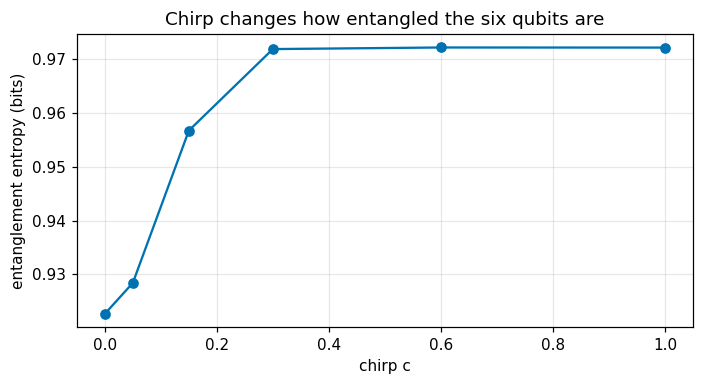

Figure: the entanglement entropy between the two halves of the register rises with the chirp and levels off just below 1 bit (values printed in the table above).


In [7]:
chirps = [0.0, 0.05, 0.15, 0.3, 0.6, 1.0]
print(f'{"chirp c":>8s} {"S(qubits 0-2 | 3-5) bits":>26s} {"CNOTs to prepare":>17s} {"total gates":>12s}')
ent = []
for cv in chirps:
    v = chirped_state(cv)
    S_ = entropy(partial_trace(Statevector(v), [0, 1, 2]), base=2)
    tq = transpile(QuantumCircuit(NQ).compose(StatePreparation(Statevector(v))), basis_gates=['cx', 'u'], optimization_level=1)
    ops = tq.count_ops()
    ent.append(S_)
    print(f'{cv:8.2f} {S_:26.4f} {ops.get("cx", 0):17d} {sum(ops.values()):12d}')
plt.figure(figsize=(6.5, 3.6))
plt.plot(chirps, ent, 'o-'); plt.xlabel('chirp c'); plt.ylabel('entanglement entropy (bits)')
plt.title('Chirp changes how entangled the six qubits are'); plt.tight_layout(); plt.show()
print('Figure: the entanglement entropy between the two halves of the register rises with the chirp and levels off '
      'just below 1 bit (values printed in the table above).')

The general-purpose preparation costs the **same 57 CNOTs for every chirp**: it treats any 64 amplitudes as arbitrary and never notices structure. The chirp itself, though, is cheap. The rolled index $j$ stores position $x$ in **6-bit two's complement**, $x = \sum_{q=0}^{4} 2^q b_q - 32\,b_5$, so with $b_q^2 = b_q$
$$\frac{c}{4}x^2 = \frac{c}{4}\Big(\sum_q w_q^2\, b_q + 2\sum_{p<q} w_p w_q\, b_p b_q\Big), \qquad w_q = 2^q\ (q<5),\ w_5 = -32$$
Each $b_q$ term is a single-qubit **phase gate** and each $b_pb_q$ term a **controlled-phase gate**: 6 + 15 gates, exactly. A quadratic phase is a sum of pairwise interactions, the same reason an optical chirp is "quadratic".

In [8]:
def chirp_circuit(cv):
    th = cv/4
    wq = [1, 2, 4, 8, 16, -32]
    qc = QuantumCircuit(NQ)
    for q in range(NQ):
        qc.p(th*wq[q]**2, q)
    for p_ in range(NQ):
        for q in range(p_ + 1, NQ):
            qc.cp(2*th*wq[p_]*wq[q], p_, q)
    return qc

from qiskit.quantum_info import Operator
cc = chirp_circuit(CHIRP)
target = np.diag(np.exp(1j*CHIRP*np.where(np.arange(DIM) < 32, np.arange(DIM), np.arange(DIM) - DIM)**2/4))
print('chirp circuit equals diag(exp(i c x^2 / 4)):', np.allclose(Operator(cc).data, target))
ops_c = transpile(cc, basis_gates=['cx', 'u'], optimization_level=1).count_ops()
print(f'gates: {dict(cc.count_ops())};  compiled: {ops_c.get("cx", 0)} CNOTs')

unchirped = chirped_state(0.0)
qc = QuantumCircuit(NQ); qc.prepare_state(Statevector(unchirped), range(NQ)); qc.compose(chirp_circuit(CHIRP), inplace=True)
print('Gaussian preparation + chirp circuit reproduces the chirped state:',
      np.isclose(abs(np.vdot(Statevector(qc).data, psi6))**2, 1.0))

chirp circuit equals diag(exp(i c x^2 / 4)): True
gates: {'cp': 15, 'p': 6};  compiled: 30 CNOTs
Gaussian preparation + chirp circuit reproduces the chirped state: True


---
## 8. Lean 4: the index bookkeeping

The code stores position $x \in [-32, 31]$ at index $j = (x + 32) \bmod 64$ via `np.roll`, and reads it back with $x = j - 32$ after rolling. The two maps must be inverse to each other, there must be exactly $2^6 = 64$ basis states, and the rolled index must be the two's-complement encoding used by the chirp circuit. Lean checks every case.

In [9]:
lean_src = r'''
-- six qubits: 2^6 basis states
theorem six_qubits : 2 ^ 6 = 64 := by decide
-- np.roll by 32 on a 64-site ring, applied twice, is the identity (rolling is undone by rolling back)
theorem roll_twice : ∀ j : Fin 64, ((j.val + 32) % 64 + 32) % 64 = j.val := by decide +kernel
-- the centered position x = j - 32 (as an integer) covers -32 .. 31 exactly once
-- the rolled index j holds position x = j for j < 32 and x = j - 64 otherwise: 6-bit two's complement
theorem twos_complement : ∀ j : Fin 64, (if j.val < 32 then (j.val : Int) else (j.val : Int) - 64) =
    ((j.val % 32 : Nat) : Int) - 32 * ((j.val / 32 : Nat) : Int) := by decide +kernel
def positions : List Int := (List.range 64).map (fun (j : Nat) => (j : Int) - 32)
theorem positions_cover : positions.length = 64 ∧ positions.head? = some (-32) ∧ positions.getLast? = some 31 ∧
    positions.Nodup := by decide +kernel
'''
lean_file = pathlib.Path.cwd() / 'chirped_gaussian_6qubit.lean'
lean_file.write_text(lean_src.strip() + '\n', encoding='utf-8')
print(lean_src.strip())
r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: exit code {r.returncode}')
print('✓ verified by the Lean kernel' if r.returncode == 0 else (r.stdout + r.stderr))

-- six qubits: 2^6 basis states
theorem six_qubits : 2 ^ 6 = 64 := by decide
-- np.roll by 32 on a 64-site ring, applied twice, is the identity (rolling is undone by rolling back)
theorem roll_twice : ∀ j : Fin 64, ((j.val + 32) % 64 + 32) % 64 = j.val := by decide +kernel
-- the centered position x = j - 32 (as an integer) covers -32 .. 31 exactly once
-- the rolled index j holds position x = j for j < 32 and x = j - 64 otherwise: 6-bit two's complement
theorem twos_complement : ∀ j : Fin 64, (if j.val < 32 then (j.val : Int) else (j.val : Int) - 64) =
    ((j.val % 32 : Nat) : Int) - 32 * ((j.val / 32 : Nat) : Int) := by decide +kernel
def positions : List Int := (List.range 64).map (fun (j : Nat) => (j : Int) - 32)
theorem positions_cover : positions.length = 64 ∧ positions.head? = some (-32) ∧ positions.getLast? = some 31 ∧
    positions.Nodup := by decide +kernel



chirped_gaussian_6qubit.lean: exit code 0
✓ verified by the Lean kernel


---
## Summary

- $|\psi(x)|^2$ is a Gaussian of width $\sigma$; the chirp is invisible to position measurement.
- The chirp is a linear sweep of local wavenumber, $k_{loc} = cx/2$.
- Momentum width $\sigma_k = \sqrt{1 + c^2\sigma^4}/(2\sigma)$, so $\sigma_x\sigma_k = \tfrac12\sqrt{1 + c^2\sigma^4}$: chirp lifts the state above the Heisenberg minimum.
- One dispersion value $a^\star$ removes the chirp and compresses the packet back to the minimum-uncertainty width, exactly like a fiber pulse compressor.
- The 64-amplitude, six-qubit state matches every closed form. On qubits it is an entangled state, and the chirp raises the entanglement between the two halves of the register.
- Generic state preparation costs 57 CNOTs whatever the chirp, but the chirp alone is exactly 6 phase + 15 controlled-phase gates, because a quadratic phase in two's-complement bits is a sum of pairwise terms.

## References

[1] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018, sec. 2.4 (the free particle and Gaussian wave packets).

[2] G. P. Agrawal, *Nonlinear Fiber Optics*, 6th ed. London, U.K.: Academic Press, 2019, ch. 3 (chirped Gaussian pulses and dispersion).

[3] M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary ed. Cambridge, U.K.: Cambridge Univ. Press, 2010.

[4] Qiskit contributors, "Qiskit: An open-source framework for quantum computing," 2023, doi: 10.5281/zenodo.2573505.

*Reference details are from memory; verify before citing.*